# 01 · Fuentes y preparación de la demanda

En este cuaderno explico cómo paso de las fuentes de movilidad a una demanda de **2.500.000 visitas-persona en 2028**, igual sin y con intervención. Preparo su distribución por periodo, hora, procedencia territorial y modo de transporte. Las visitas siguen siendo las mismas; los transbordos y los viajes de regreso no se convierten en nuevos visitantes.

**Qué recibe:** el registro abierto o creado en [00 · Inicio y referencia](00_inicio_y_referencia.ipynb), las fuentes Bronze y las decisiones de configuración identificadas. **Qué produce:** si se elige calcular, 26 tablas de demanda con sus metadatos y huellas en la etapa 01 de esa ejecución. **Qué comprueba:** conservación de visitas, reparto por modos, calendario y procedencia. Las 21 comparaciones con Silver son una fase posterior, separada de la preparación.

Aquí no calculo distancias energéticas, capacidad de lanzaderas, consumo o ahorro. La demanda obtenida será una entrada de los recorridos, del servicio y del balance. El cálculo científico permanece en [demanda/preparacion.py](../src/movilidad_teide/demanda/preparacion.py); las celdas llaman al productor común y organizan sus tablas para explicarlas.


## 1. Abrir la misma ejecución y elegir la acción

`consultar` lee la demanda ya completada de la ejecución seleccionada. `calcular` llama al productor registrado de 01 para preparar una demanda nueva desde Bronze. En este caso la ejecución debe haberse iniciado en 00 y no tener ya la etapa completada. Si la tiene, creo otra ejecución; no la sobrescribo.

**La ruta debe coincidir con la elegida en 00.** Este cuaderno abre su propio proceso y vuelve a comprobar el registro; no necesita ninguna variable del cuaderno anterior. En una sesión nueva reinicio y ejecuto las celdas en orden. Los dos controles siguientes no permiten editar visitas, ocupaciones o cupos: esas hipótesis proceden del Excel validado.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown

candidatas = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RAIZ = next((p for p in candidatas if (p / "pyproject.toml").is_file()
             and (p / "config/parametros_modelo.xlsx").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este cuaderno desde la raíz del proyecto o desde notebooks/.")
sys.path.insert(0, str(RAIZ / "src"))
from movilidad_teide.configuracion.registro import abrir_ejecucion, resumen_ejecucion


In [2]:
ACCION_DEMANDA = "consultar"  # Alternativa explícita: "calcular".
RUTA_EJECUCION = Path("data/silver/ejecuciones/referencia_2028_final_20261116")


In [3]:
from movilidad_teide.flujos.etapas_registradas import ejecutar_etapa

if ACCION_DEMANDA not in {"consultar", "calcular"}:
    raise ValueError('ACCION_DEMANDA debe ser "consultar" o "calcular".')
EJECUCION = RAIZ / RUTA_EJECUCION
if not (EJECUCION / "registro_ejecucion.json").is_file():
    raise FileNotFoundError("No existe el registro seleccionado. Inicie la ejecución en 00 e indique aquí esa misma ruta antes de calcular o consultar.")
DATOS = abrir_ejecucion(RAIZ, EJECUCION)
if ACCION_DEMANDA == "calcular":
    RESULTADO_ETAPA = ejecutar_etapa(RAIZ, EJECUCION, "01", accion="calcular")
    DATOS = abrir_ejecucion(RAIZ, EJECUCION)
ETAPA = DATOS["estado_etapas"]["etapas"]["01"]
if ETAPA["estado"] != "completada":
    raise ValueError("No hay demanda completada. Inicie la ejecución en 00 y elija calcular en 01.")
CARPETA_DEMANDA = EJECUCION / ETAPA["carpeta"]
METADATOS = json.loads((CARPETA_DEMANDA / "metadatos.json").read_text())
TABLAS = {fila["producto"]: pd.read_parquet(CARPETA_DEMANDA / "tablas_parquet" / (fila["producto"] + ".parquet"))
          for fila in METADATOS["resumen_tablas"]}
OBJETIVO_VISITAS = DATOS["configuracion"]["valores"]["visitas_anio"]
print("Acción realizada:", ACCION_DEMANDA)
print("Ejecución:", DATOS["registro"]["identificador"])
print("Carpeta de las tablas, dentro de esa ejecución:", ETAPA["carpeta"])
print("Tablas preparadas:", len(TABLAS))
print("Energía calculada por esta preparación:", "Sí" if METADATOS["energia_recalculada"] else "No")


Acción realizada: consultar
Ejecución: referencia_2028_paquetes_20261116
Carpeta de las tablas, dentro de esa ejecución: resultados/01/bec978f433644f97a256a6878c6d8f1d
Tablas preparadas: 26
Energía calculada por esta preparación: No


## 2. Entender las fuentes antes de combinarlas

Las fuentes miden magnitudes distintas y tienen periodos y coberturas diferentes. La tabla 1 explica qué aporta cada una. **No sumo aforos, matrices y pasajeros como si fueran visitantes adicionales.** Utilizo sus patrones y proporciones para distribuir una demanda de planificación fijada de manera explícita.

**Tabla 1. Fuentes de la demanda, unidad de origen y función en la preparación de 2028.**

| Fuente y ubicación Bronze | Qué contiene | Cómo se utiliza y qué no demuestra |
|---|---|---|
| Visor Teide: `documentacion/visor_teide/` | Matrices y perfiles publicados de movilidad, con periodos y formatos identificados | Forma temporal y territorial de la demanda. Las propuestas operativas del Visor no se adoptan automáticamente |
| Aforos: `aforos/` | Conteos de vehículos por punto, sentido, categoría y hora | Estimación del reparto entre coche y transporte colectivo, con ocupaciones explícitas. Los pasos no son personas únicas ni visitas |
| Consultas de origen y destino: `demanda/odviewer/` | Matrices y perfiles horarios de relaciones entre zonas; OD significa origen-destino | Cobertura y coherencia de los viajes publicados. Se seleccionan consultas completas; una consulta filtrada no representa el mismo universo |
| Zonificación y paradas: fuentes de OD y `transporte_publico/gtfs/` | Zonas geográficas y oferta de transporte público en GTFS, formato de horarios, recorridos y paradas | Correspondencias territoriales y puntos de referencia; las paradas no observan por sí mismas el origen real de cada visitante |
| Pasajeros TITSA: `transporte_publico/pasajeros_titsa/2025/` | Matrices mensuales de viajeros y paradas | Separación de accesos, salidas y viajes interiores; no contienen consumo de combustible |
| Estimación oficial de visitas: `documentacion/visitas_parque/` | Informe del Organismo Autónomo Parques Nacionales (OAPN), resultados de 2025 publicados en 2026 | Contexto y normalización intermedia de la preparación. No fija por sí solo la demanda de planificación de 2028 |
| Excel y reglas: `config/` | Condiciones efectivas y correspondencias elegidas | Volumen anual de planificación y reglas identificadas; una hipótesis no se presenta como observación |

Fuente: [contrato de fuentes y comparaciones](../manifiestos/preparacion_demanda_bronze.json) y [trazabilidad de la demanda](../manifiestos/trazabilidad_preparacion_demanda.csv). Las ubicaciones de datos de la tabla parten de `data/bronze/`. El contrato identifica 300 archivos de fuentes y configuración, incluidos auxiliares necesarios para interpretar formatos. Los títulos, procedencia y condiciones de distribución se conservan en sus metadatos y en las [atribuciones](../ATRIBUCIONES.md).

La secuencia es: **extraer las fuentes → revisar cobertura y unidades → obtener proporciones y referencias territoriales → fijar 2.500.000 visitas → distribuirlas por tiempo, origen y modo**. La comparación con las tablas de referencia se realiza después, sin usar sus cifras para preparar las nuevas.


## 3. Seleccionar las matrices y conservar su alcance

La captura del Visor contiene 57 matrices de distintos periodos. La tabla 2 las agrupa por año y formato; el fichero completo conserva la correspondencia de cada matriz publicada con su índice técnico. Algunas correspondencias se infieren por un total compatible con el redondeo: ese estado se conserva y no se presenta como confirmación recibida.

Las consultas OD completas seleccionadas de 2025 se comprueban por separado en la tabla 3. Se conservan viajes, relaciones y cobertura horaria. La selección de meses y tipos de día aporta perfiles representativos, no un registro observado de cada fecha de 2028. Los lectores y extractores están en [fuentes/preparacion_demanda.py](../src/movilidad_teide/fuentes/preparacion_demanda.py).


In [4]:
indices = TABLAS["visor/indices"]
resumen_matrices = indices.groupby(["anio", "formato_publicado"], as_index=False).agg(Matrices=("matrix_index", "size"))
resumen_matrices = resumen_matrices.rename(columns={"anio": "Año de referencia", "formato_publicado": "Formato publicado"})
display(resumen_matrices.style.set_uuid("demanda_matrices").hide(axis="index")
        .set_caption("Tabla 2. Matrices de movilidad del Visor por año y formato. Fuente: visor/indices, ejecución seleccionada; 57 matrices en la captura."))
od = TABLAS["od/resumen_consultas"]
resumen_od = od.groupby(["anio", "mes", "tipo_dia"], as_index=False).agg(
    Consultas=("id_matriz", "size"), Relaciones_OD=("relaciones_od", "sum"),
    Controles_correctos=("control_od_horario", "all"))
resumen_od = resumen_od.rename(columns={"anio": "Año", "mes": "Mes fuente", "tipo_dia": "Tipo de día",
    "Relaciones_OD": "Relaciones OD registradas", "Controles_correctos": "Totales OD/horarios coherentes"})
display(resumen_od.style.set_uuid("demanda_od").hide(axis="index")
        .set_caption("Tabla 3. Cobertura de las consultas OD seleccionadas de 2025. Fuente: od/resumen_consultas, ejecución seleccionada; las relaciones de consultas distintas no son visitas únicas."))


Año de referencia,Formato publicado,Matrices
2021,Formato 2021,9
2022,Formato 2021,14
2023,Formato 2021,7
2023,Formato 2025,6
2024,Formato 2025,9
2025,Formato 2025,9
2026,Formato 2025,3


Año,Mes fuente,Tipo de día,Consultas,Relaciones OD registradas,Totales OD/horarios coherentes
2025,3,domingo,4,1510,True
2025,3,laborable,4,1391,True
2025,3,sabado,4,1535,True
2025,7,domingo,4,1382,True
2025,7,laborable,4,1156,True
2025,7,sabado,4,1346,True
2025,10,domingo,4,1411,True
2025,10,laborable,4,1232,True
2025,10,sabado,4,1371,True


## 4. Pasar de conteos de vehículos a un reparto estimado de personas

Los aforos describen pasos de vehículos. Para estimar personas aplico ocupaciones documentadas a las categorías de coche y autocar. La tabla 4 presenta la fila condicionada efectivamente utilizada para las entradas de 2025; no mezcla esa estimación con las filas diagnósticas que conservan valores incompletos.

Para reproducir esta preparación conservo en Bronze el libro original del que proceden sus dos ocupaciones, identificado por su huella. **Ese documento es una fuente inmutable, no otro editor de hipótesis.** Las condiciones vigentes del proyecto se editan únicamente en el Excel mostrado en 00. El [metadato del libro de origen](../data/bronze/documentacion/preparacion_aforos/procedencia.json) explica su procedencia.

Antes del reparto se aplica la corrección de marcas de fecha ya documentada en la fuente de 2025: 89 medianoches de octubre a diciembre estaban asignadas al día anterior en cada una de las 16 series de 8.760 horas. El lector verifica el patrón antes de corregirlo. Se mantienen valores decimales, negativos y ausencias; no se sustituyen extremos para forzar un resultado. Esta corrección no confirma una conversión entre hora civil y UTC —tiempo universal coordinado—. La cobertura por punto y categoría se conserva en `aforos/resumen_anual`.


La política de `.gitignore` determina la disponibilidad documental. Con reserva se comprueban el cálculo, sus referencias obligatorias y las matrices; los documentos reservados se identifican expresamente y no se declara comprobación de sus bytes. Sin reserva se exige también su presencia e integridad.


In [5]:
af = TABLAS["aforos/reparto_personas_aforos_conjunto"]
seleccion_aforo = af.loc[af["anio"].eq(2025) & af["sentido"].eq("entrada") & af["ocupacion_coche_aplicada"].notna()]
if len(seleccion_aforo) != 1:
    raise ValueError("La preparación no identifica una fila única de reparto de entradas de 2025.")
fila_aforo = seleccion_aforo.iloc[0]
reparto_aforo = pd.DataFrame([
    {"Medio": "Coche", "Ocupación aplicada (personas/vehículo)": fila_aforo["ocupacion_coche_aplicada"],
     "Proporción estimada de personas (%)": fila_aforo["fraccion_personas_paso_en_coche"] * 100},
    {"Medio": "Autocar equivalente", "Ocupación aplicada (personas/vehículo)": fila_aforo["ocupacion_guagua_aplicada"],
     "Proporción estimada de personas (%)": fila_aforo["fraccion_personas_paso_en_guagua"] * 100}])
display(reparto_aforo.style.set_uuid("demanda_aforos").hide(axis="index").format(precision=2, decimal=",", thousands=" ")
        .set_caption("Tabla 4. Reparto condicionado de personas a partir de aforos de entrada de 2025. Fuente: aforos/reparto_personas_aforos_conjunto; son estimaciones, no ocupaciones medidas vehículo a vehículo."))


Medio,Ocupación aplicada (personas/vehículo),Proporción estimada de personas (%)
Coche,"3,20","76,31"
Autocar equivalente,"35,99","23,69"


## 5. Representar los orígenes sin atribuir precisión individual

Las 233 zonas se agrupan en 41 orígenes de cálculo. La tabla 5 resume cuántas zonas y orígenes corresponden a cada agrupación territorial. Son representaciones de conjuntos de viajes, no localizaciones observadas de cada persona. La relación completa de zonas está en `territorio/correspondencia` y los municipios y referencias territoriales, en `territorio/origenes`. La localización adoptada para calcular recorridos se prepara en 02; las columnas diagnósticas de puntos de esta fase no se presentan como esa elección definitiva.

Las cabeceras utilizadas por el estudio siguen las correspondencias declaradas, incluidas las reasignaciones adoptadas. Distingo el corredor de la fuente del corredor de cálculo. En 02 se explicarán sus recorridos y aproximaciones geográficas; aquí no obtengo distancias ni pendientes nuevas. Los colectivos —visitantes extranjeros, visitantes de España no Tenerife y las dos categorías de residentes de Tenerife de la fuente— conservan sus pesos y no se convierten en visitantes adicionales.


In [6]:
correspondencia = TABLAS["territorio/correspondencia"]
origenes = TABLAS["territorio/origenes"]
agrupaciones = origenes.groupby("macrozona", as_index=False).agg(
    Origenes=("origen_id", "nunique"), Zonas=("numero_zonas", "sum"))
agrupaciones = agrupaciones.rename(columns={"macrozona": "Agrupación territorial", "Origenes": "Orígenes de cálculo", "Zonas": "Zonas agrupadas"})
display(agrupaciones.style.set_uuid("demanda_origenes").hide(axis="index").format(na_rep="No disponible")
        .set_caption("Tabla 5. Zonas y orígenes representativos por agrupación territorial. Fuente: territorio/origenes, ejecución seleccionada; total 233 zonas y 41 orígenes, sin adoptar todavía los puntos de los recorridos de 02."))
print("Zonas con correspondencia:", correspondencia["zona_id"].nunique())
print("Orígenes representativos:", origenes["origen_id"].nunique())


Agrupación territorial,Orígenes de cálculo,Zonas agrupadas
Abona,5,55
Acentejo,6,13
Icoden-Daute-Isla Baja,8,16
Laguna Centro,1,21
Laguna Norte - Tegueste,2,12
Sureste,3,11
Suroeste,4,33
Tenerife Centro - Anaga,2,26
Tenerife Sur - El Rosario,2,13
Valle de Güímar,5,17


Zonas con correspondencia: 233
Orígenes representativos: 41


## 6. Separar los pasajeros TITSA de las visitas adicionales

Las matrices de TITSA contienen pasajeros-tramo, es decir, personas transportadas entre una parada de entrada y otra de salida. La preparación distingue tramos que entran o salen del Parque, tramos interiores y tramos exteriores usando las paradas y el límite geográfico del Parque. La tabla 6 conserva esos ámbitos por línea; no los suma como personas únicas.

Para el reparto del estudio, las entradas se interpretan como visitas por hipótesis y se anualizan con los tipos de día disponibles. **No se añade TITSA por encima del total de visitas:** se separa su participación dentro de la demanda. Su asignación territorial es una representación de cálculo, no una observación del origen de cada viajero. La oferta de horarios tampoco equivale a combustible consumido.

La cobertura mensual está en `titsa/cobertura`; las referencias diarias y la anualización, en `titsa/referencias_diarias` y `titsa/estimacion_anual`. El balance posterior incorpora la sustitución de los accesos 342 y 348 y el coche hasta las cabeceras. No se deducen sus kilómetros ni su consumo de esta tabla de pasajeros.


In [7]:
titsa = TABLAS["titsa/estimacion_anual"]
titsa_ambitos = titsa.groupby(["linea_id", "ambito_fisico"], as_index=False)["pasajeros_tramo_anuales_equivalentes"].sum()
titsa_ambitos = titsa_ambitos.rename(columns={"linea_id": "Línea TITSA", "ambito_fisico": "Ámbito físico del tramo",
    "pasajeros_tramo_anuales_equivalentes": "Pasajeros-tramo/año equivalentes (referencia 2025)"})
display(titsa_ambitos.style.set_uuid("demanda_titsa").hide(axis="index").format(precision=2, decimal=",", thousands=" ")
        .set_caption("Tabla 6. Referencia anualizada de viajeros TITSA por línea y ámbito. Fuente: titsa/estimacion_anual; no sumar entrada y salida para obtener visitas."))


Línea TITSA,Ámbito físico del tramo,Pasajeros-tramo/año equivalentes (referencia 2025)
341,entrada,"0,00"
341,exterior,"0,00"
341,interior,"3 711,96"
341,salida,"0,00"
342,entrada,"6 344,38"
342,exterior,"4 305,95"
342,interior,"931,62"
342,salida,"7 260,83"
348,entrada,"7 378,90"
348,exterior,"6 092,86"


## 7. Fijar el volumen de planificación de 2028

La estimación oficial para 2025 y el volumen de este estudio tienen funciones diferentes. La tabla 7 los presenta juntos para evitar que una escala intermedia se confunda con la demanda evaluada.

Las tasas comparables de la fuente sirven para preparar sus referencias y la proyección específica de TITSA. **Después se normaliza el conjunto a 2.500.000 visitas-persona.** No aplico otra tasa de crecimiento a esos 2,5 millones. Tampoco supongo que la estimación oficial de 2025 valide las ocupaciones, recorridos o capacidades del proyecto.


In [8]:
fuente_visitas = json.loads((RAIZ / "data/bronze/documentacion/visitas_parque/metadatos_2025.json").read_text())
escalas = pd.DataFrame([
    {"Magnitud": "Estimación oficial del Teide", "Año": fuente_visitas["anio"],
     "Visitas-persona/año": fuente_visitas["visitas_anuales"], "Función": "Contexto y normalización intermedia de la preparación"},
    {"Magnitud": "Demanda de planificación en cada escenario", "Año": 2028,
     "Visitas-persona/año": OBJETIVO_VISITAS, "Función": "Total que se mantiene sin y con intervención"}])
display(escalas.style.set_uuid("demanda_escalas").hide(axis="index").format({"Año": "{:d}", "Visitas-persona/año": "{:,.0f}"}, thousands=" ")
        .set_caption("Tabla 7. Escala oficial de contexto y demanda evaluada. Fuentes: OAPN, resultados 2025, publicado en mayo de 2026, p. 7; Excel de hipótesis de la ejecución. No son dos escenarios de demanda a sumar."))


Magnitud,Año,Visitas-persona/año,Función
Estimación oficial del Teide,2025,5 113 021,Contexto y normalización intermedia de la preparación
Demanda de planificación en cada escenario,2028,2 500 000,Total que se mantiene sin y con intervención


## 8. Distribuir las visitas en el tiempo sin multiplicar el total

La preparación construye dos repartos alternativos: **Estacional**, que conserva la variación mensual representada por las referencias, y **Media anual**, que ofrece un contraste temporal más uniforme. Ambos abarcan los 366 días de 2028 y contienen las mismas 2.500.000 visitas. No se suman: son dos maneras de repartir el mismo año. El balance principal utiliza el reparto estacional.

Cada reparto utiliza 36 perfiles: para cada mes se representan los tipos de día laborable, sábado y domingo. Sus filas se desglosan además por acceso, hora y colectivo. El campo `dias_calendario` indica cuántos días representa cada perfil; por eso se multiplica la demanda del día tipo por ese peso al obtener el total anual. Sumar esa columna en todas las filas contaría los mismos días muchas veces.

La tabla 8 comprueba los totales. La figura 1 muestra las visitas mensuales del reparto estacional, antes de aplicar cupos o transferencias a las lanzaderas. Es una distribución de planificación, no una previsión exacta de llegadas diarias. El **percentil 85** utilizado al estudiar la capacidad es un nivel que deja por debajo o igual al 85 % de los valores de su muestra; no es un máximo garantizado. Los extremos de acceso y la respuesta operativa a las puntas se interpretan en el estudio del servicio.


In [9]:
import numpy as np

horaria = TABLAS["calendario/demanda_horaria_calendario"]
resumen_calendario = []
for metodo, grupo in horaria.groupby("metodo_calendario", sort=True):
    if grupo.groupby("id_perfil")["dias_calendario"].nunique().max() != 1:
        raise ValueError("Un perfil tiene pesos de calendario incoherentes.")
    dias = grupo[["id_perfil", "dias_calendario"]].drop_duplicates()["dias_calendario"].sum()
    visitas = float((grupo["visitas_persona_dia"] * grupo["dias_calendario"]).sum())
    np.testing.assert_allclose(visitas, OBJETIVO_VISITAS, rtol=0, atol=1e-8)
    resumen_calendario.append({"Reparto temporal alternativo": metodo, "Perfiles de día tipo": grupo["id_perfil"].nunique(),
        "Días representados en 2028": dias, "Visitas-persona/año": visitas,
        "Diferencia respecto al total del Excel": visitas - OBJETIVO_VISITAS})
display(pd.DataFrame(resumen_calendario).style.set_uuid("demanda_calendarios").hide(axis="index")
        .format(precision=2, decimal=",", thousands=" ")
        .set_caption("Tabla 8. Conservación del total anual en los dos repartos alternativos de 2028. Fuente: calendario/demanda_horaria_calendario; tolerancia absoluta 10⁻⁸ visitas. No sumar ambos repartos."))


Reparto temporal alternativo,Perfiles de día tipo,Días representados en 2028,Visitas-persona/año,Diferencia respecto al total del Excel
Estacional,36,366,"2 500 000,00","0,00"
Media anual,36,366,"2 500 000,00","0,00"


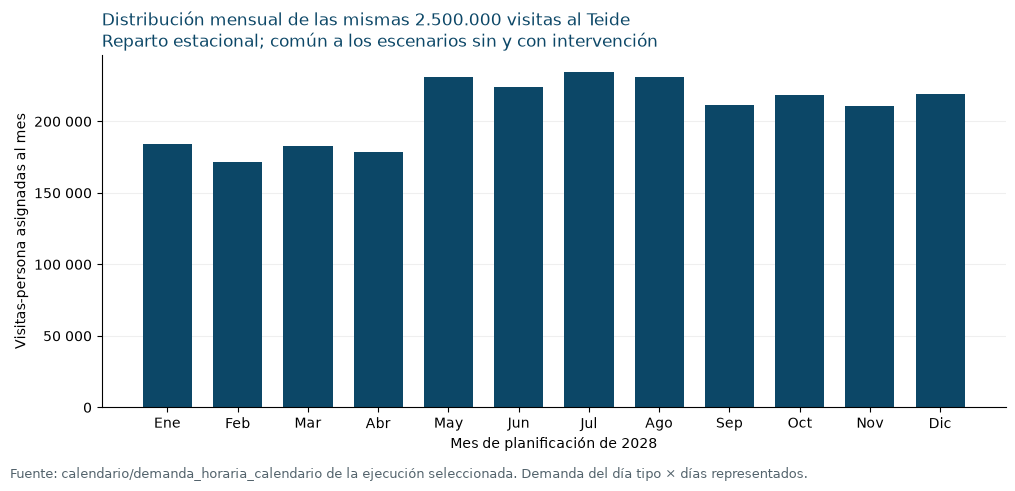

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

estacional = horaria.loc[horaria["metodo_calendario"].eq("Estacional")].copy()
mensual = (estacional.assign(visitas_ponderadas=estacional["visitas_persona_dia"] * estacional["dias_calendario"])
           .groupby("mes_modelo")["visitas_ponderadas"].sum().reindex(range(1, 13)))
if mensual.isna().any():
    raise ValueError("Falta un mes en el reparto estacional.")
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax.bar(range(1, 13), mensual.to_numpy(), color="#0C4767", width=0.7)
ax.set_xticks(range(1, 13), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_ylabel("Visitas-persona asignadas al mes")
ax.set_xlabel("Mes de planificación de 2028")
ax.set_title("Distribución mensual de las mismas 2.500.000 visitas al Teide\nReparto estacional; común a los escenarios sin y con intervención", loc="left", color="#0C4767")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", " ")))
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.text(0, -0.05, "Fuente: calendario/demanda_horaria_calendario de la ejecución seleccionada. Demanda del día tipo × días representados.", fontsize=9, color="#53636C")
plt.show()
plt.close(fig)


**Figura 1. Distribución mensual de la demanda de planificación del Teide en 2028.** Se representa únicamente el reparto estacional y el total común a ambos escenarios, antes de ordenar el transporte. Fuente: `calendario/demanda_horaria_calendario`, ejecución seleccionada; elaboración propia por suma de la demanda ponderada de cada mes. La mayor o menor altura de una barra no acredita que la flota cubra cada fecha: esa comprobación corresponde al servicio.


## 9. Comprobar el reparto de acceso antes de ordenar el transporte

La tabla 9 agrupa las visitas del reparto estacional por modo **sin intervención**: coche, servicios TITSA y excursiones. Son categorías de acceso de las mismas visitas al Parque. Las cifras son estimaciones anuales y se muestran con decimales para conservar su conciliación; no son recuentos de personas identificadas. Las visitas en coche representan ocupantes: el número de vehículos se obtiene utilizando la ocupación correspondiente, no identificando una persona con un coche.

Este reparto no es todavía el de la intervención: el cupo, la demanda que pasa a lanzadera, las cabeceras y las cadenas de ida y regreso se comprueban en 04. Las excursiones se mantienen en la comparación principal. Sus posibles incrementos se estudian después como redistribución de las mismas visitas, sin suponer aquí visitantes nuevos.


In [11]:
columnas_modo = {"visitas_coche": "Coche particular", "visitas_titsa": "Servicios TITSA",
                 "visitas_excursiones_resto_colectivo": "Excursiones"}
filas_modo = []
for columna, nombre in columnas_modo.items():
    visitas = float((estacional[columna] * estacional["dias_calendario"]).sum())
    filas_modo.append({"Modo de acceso sin intervención": nombre, "Visitas-persona/año": visitas,
                       "Porcentaje del total anual (%)": visitas / OBJETIVO_VISITAS * 100})
modos = pd.DataFrame(filas_modo)
np.testing.assert_allclose(modos["Visitas-persona/año"].sum(), OBJETIVO_VISITAS, rtol=0, atol=1e-8)
display(modos.style.set_uuid("demanda_modos").hide(axis="index").format(precision=2, decimal=",", thousands=" ")
        .set_caption("Tabla 9. Visitas por modo de acceso sin intervención en 2028. Fuente: reparto estacional de calendario/demanda_horaria_calendario; denominador 2.500.000 visitas-persona/año. No incluye embarques ni servicios de autobús."))
print("Total conciliado de visitas-persona/año:", f'{modos["Visitas-persona/año"].sum():,.2f}'.replace(",", " "))


Modo de acceso sin intervención,Visitas-persona/año,Porcentaje del total anual (%)
Coche particular,"1 907 863,20","76,31"
Servicios TITSA,"13 786,07","0,55"
Excursiones,"578 350,73","23,13"


Total conciliado de visitas-persona/año: 2 500 000.00


## 10. Localizar las tablas y entender qué está comprobado

La tabla 10 identifica los 26 productos de demanda, su número de filas y columnas y su ruta dentro de la carpeta de 01 mostrada al abrir. Cada producto se conserva en CSV —texto con filas y columnas—, para lectura, y Parquet, un formato de tablas que mantiene los tipos de las columnas para las etapas siguientes. Sus huellas, las fuentes y las lecturas observadas están en `metadatos.json` y en el cierre de la etapa.

**Conservar el total no basta para probar toda la preparación.** El contrato define además 21 interfaces que comparan claves, cantidades, ausencias y textos con Silver, con tolerancia numérica absoluta de 10⁻⁸. No compara todas las columnas de todos los productos: su alcance exacto está en el [contrato](../manifiestos/preparacion_demanda_bronze.json). Por ejemplo, la comprobación de una tabla territorial no certifica sus perfiles energéticos.

Si la ejecución elegida ya completó 07, muestro su comparación registrada de demanda en la tabla 11. Si solo se han calculado 00–01, esa comparación figura como pendiente y no se atribuye al nuevo cálculo una comprobación de otra ejecución. El control se realiza después en 07; los comandos disponibles mientras se adapta ese cuaderno están en la [guía de etapas](../docs/ejecucion_por_etapas.md). La [guía de demanda](../docs/preparacion_demanda.md) documenta también la comparación independiente en un destino nuevo.


In [12]:
productos = pd.DataFrame(METADATOS["resumen_tablas"]).rename(columns={
    "producto": "Producto de demanda", "filas": "Filas", "columnas": "Columnas"})
productos["CSV relativo a 01"] = "tablas/" + productos["Producto de demanda"] + ".csv"
productos["Parquet relativo a 01"] = "tablas_parquet/" + productos["Producto de demanda"] + ".parquet"
display(productos.style.set_uuid("demanda_productos").hide(axis="index")
        .set_caption("Tabla 10. Inventario completo de las tablas de demanda aceptadas en esta ejecución. Fuente: metadatos.json de 01; las filas son registros de cada tabla y no se suman como visitas."))


Producto de demanda,Filas,Columnas,CSV relativo a 01,Parquet relativo a 01
visor/perfiles,10300,9,tablas/visor/perfiles.csv,tablas_parquet/visor/perfiles.parquet
visor/centroides,7759,12,tablas/visor/centroides.csv,tablas_parquet/visor/centroides.parquet
visor/rutas,8,6,tablas/visor/rutas.csv,tablas_parquet/visor/rutas.parquet
visor/inventario,27,7,tablas/visor/inventario.csv,tablas_parquet/visor/inventario.parquet
visor/controles,3,4,tablas/visor/controles.csv,tablas_parquet/visor/controles.parquet
visor/indices,57,10,tablas/visor/indices.csv,tablas_parquet/visor/indices.parquet
aforos/resumen_anual,112,15,tablas/aforos/resumen_anual.csv,tablas_parquet/aforos/resumen_anual.parquet
aforos/resumen_mensual,1344,16,tablas/aforos/resumen_mensual.csv,tablas_parquet/aforos/resumen_mensual.parquet
aforos/comparacion_tendencias,36,10,tablas/aforos/comparacion_tendencias.csv,tablas_parquet/aforos/comparacion_tendencias.parquet
aforos/reparto_personas_aforos_conjunto,8,27,tablas/aforos/reparto_personas_aforos_conjunto.csv,tablas_parquet/aforos/reparto_personas_aforos_conjunto.parquet


In [13]:
estado_comparacion = DATOS["estado_etapas"]["etapas"]["07"]
if estado_comparacion["estado"] == "completada":
    carpeta_control = EJECUCION / estado_comparacion["carpeta"] / "demanda"
    verificacion = json.loads((carpeta_control / "verificacion.json").read_text())
    if not verificacion["equivalente"]:
        raise ValueError("La comparación registrada de demanda no es equivalente.")
    comparaciones = pd.read_csv(carpeta_control / "comparacion_equivalencia.csv", sep=";")
    comparaciones = comparaciones[["producto", "equivalente", "maxima_diferencia_absoluta"]].rename(columns={
        "producto": "Interfaz comparada", "equivalente": "Equivalente con su referencia Silver",
        "maxima_diferencia_absoluta": "Máxima diferencia numérica (unidad original)"})
    display(comparaciones.style.set_uuid("demanda_comparacion").hide(axis="index")
            .format(na_rep="No aplica")
            .set_caption("Tabla 11. Comparación posterior de las 21 interfaces de demanda de esta misma ejecución. Fuente: comprobación de demanda registrada en 07; tolerancia absoluta 10⁻⁸ en unidades originales."))
    print("Comparación registrada de demanda: completada y equivalente.")
else:
    display(Markdown("**Comparación con Silver pendiente en esta ejecución.** La demanda está completada y sus totales se han comprobado aquí. La comparación de las 21 interfaces se realizará después; no se reutiliza el resultado de otra ejecución."))


Interfaz comparada,Equivalente con su referencia Silver,Máxima diferencia numérica (unidad original)
aforos/resumen_anual,True,0.000000
aforos/comparacion_tendencias,True,0.000000
aforos/reparto_personas_aforos_conjunto,True,0.000000
visor/rutas,True,0.000000
visor/inventario,True,0.000000
visor/controles,True,0.000000
od/resumen_consultas,True,0.000000
od/perfiles_zonas,True,0.000000
zonas/referencias,True,0.000000
zonas/municipios,True,0.000000


Comparación registrada de demanda: completada y equivalente.


## 11. Qué recibe el siguiente paso y cuáles son los límites

El siguiente paso de recorridos y pendientes recibirá la demanda territorial y sus correspondencias de esta ejecución; el servicio utilizará la demanda por hora, acceso y colectivo. Los productos se localizan por su registro y sus huellas, no por elegir automáticamente el archivo más reciente de una carpeta.

La normalización garantiza que el modelo conserve las mismas visitas bajo sus hipótesis. No elimina incertidumbres de las fuentes: cobertura temporal, ocupaciones supuestas, correspondencias territoriales, calidad de aforos y comportamiento en fechas extremas. Los perfiles de día tipo no garantizan cubrir todos los valores extremos observados. La oferta y las medidas de punta deben comprobarse antes de interpretar el ahorro como alcanzable.

Continúo con [02 · Recorridos y pendientes](02_recorridos_y_pendientes.ipynb), utilizando **esta misma ruta de ejecución**. Sus acciones permiten consultar la geografía o calcularla con la demanda ya preparada. Los comandos de la [guía común de etapas](../docs/ejecucion_por_etapas.md) son una alternativa equivalente. No es necesario repetir 01 si ya está completada. El [mapa del recorrido](../docs/recorrido_notebooks.md) sitúa el servicio antes de COPERT y el balance. El informe y sus anexos siguen identificados por su entrega vigente; ejecutar este cuaderno no los modifica.
